Name: Bisrat Amare
ID : UGR 0017/16
Stream: Software

# Machine Learning Lab 3
## Predicting Software Support Ticket Resolution Time

### Objective
The objective of this experiment is to predict software support ticket
resolution time in hours using regression models.

The models compared are:
- Dummy Regressor
- Linear Regression
- Polynomial Regression (degrees 2 and 3)
- Ridge Regression
- Lasso Regression

The models are evaluated using MAE, MSE, RMSE, and R².
Cross-validation is used to compare model settings on the training data.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_val_score,
    GridSearchCV
)
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Load the dataset
df = pd.read_csv("lab_ticket_resolution.csv")

# Inspect the dataset
print("Dataset shape:", df.shape)

print("\nFirst five rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nDescriptive statistics:")
display(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (240, 6)

First five rows:


,ticket_id,complexity_score,lines_changed,team_experience_years,reopened,resolution_hours
0,T0001,6,67,5.6,1,24.77
1,T0002,9,72,11.5,0,33.43
2,T0003,6,49,3.3,0,17.82
3,T0004,5,50,9.6,1,19.54
4,T0005,3,33,6.4,1,11.04



Data types:
ticket_id                    str
complexity_score           int64
lines_changed              int64
team_experience_years    float64
reopened                   int64
resolution_hours         float64
dtype: object

Descriptive statistics:


,complexity_score,lines_changed,team_experience_years,reopened,resolution_hours
count,240.000000,240.000000,240.000000,240.000000,240.000000
mean,5.491667,54.820833,6.105417,0.233333,19.361125
std,2.979697,26.145017,3.391426,0.423836,10.035058
min,1.000000,1.000000,0.500000,0.000000,0.500000
25%,3.000000,33.000000,3.300000,0.000000,11.015000
50%,5.500000,54.000000,5.800000,0.000000,19.610000
75%,8.000000,74.000000,9.200000,0.000000,27.122500
max,10.000000,113.000000,12.000000,1.000000,42.500000



Missing values:
ticket_id                0
complexity_score         0
lines_changed            0
team_experience_years    0
reopened                 0
resolution_hours         0
dtype: int64

Duplicate rows: 0


In [2]:
# Select features available at the intended prediction time
features = [
    "complexity_score",
    "team_experience_years"
]

X = df[features]
y = df["resolution_hours"]

# Split the data: 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training feature shape: (192, 2)
Testing feature shape: (48, 2)
Training target shape: (192,)
Testing target shape: (48,)


In [3]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

polynomial_results = []

for degree in [2, 3]:
    polynomial_model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )

    cv_scores = cross_val_score(
        polynomial_model,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error"
    )

    mean_cv_mae = -cv_scores.mean()

    polynomial_results.append({
        "Degree": degree,
        "Mean CV MAE (hours)": mean_cv_mae
    })

polynomial_comparison = pd.DataFrame(polynomial_results)
display(polynomial_comparison)

best_degree = int(
    polynomial_comparison.loc[
        polynomial_comparison["Mean CV MAE (hours)"].idxmin(),
        "Degree"
    ]
)

print("Best polynomial degree based on CV MAE:", best_degree)

,Degree,Mean CV MAE (hours)
0,2,3.131261
1,3,3.162003


Best polynomial degree based on CV MAE: 2


In [4]:
# 1. Dummy Regressor baseline
baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

# 2. Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# 3. Polynomial Regression using the best CV degree
polynomial_model = make_pipeline(
    PolynomialFeatures(degree=best_degree, include_bias=False),
    StandardScaler(),
    LinearRegression()
)
polynomial_model.fit(X_train, y_train)

# 4. Ridge Regression: tune alpha using training data only
ridge_search = GridSearchCV(
    estimator=make_pipeline(StandardScaler(), Ridge()),
    param_grid={"ridge__alpha": [0.01, 0.1, 1, 10, 100]},
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1
)
ridge_search.fit(X_train, y_train)
ridge_model = ridge_search.best_estimator_

# 5. Lasso Regression: tune alpha using training data only
lasso_search = GridSearchCV(
    estimator=make_pipeline(
        StandardScaler(),
        Lasso(max_iter=100000)
    ),
    param_grid={"lasso__alpha": [0.001, 0.01, 0.1, 1, 10]},
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1
)
lasso_search.fit(X_train, y_train)
lasso_model = lasso_search.best_estimator_

print("Selected polynomial degree:", best_degree)
print("Selected Ridge alpha:", ridge_search.best_params_["ridge__alpha"])
print("Selected Lasso alpha:", lasso_search.best_params_["lasso__alpha"])
print("All models trained successfully.")

Selected polynomial degree: 2
Selected Ridge alpha: 0.01
Selected Lasso alpha: 0.001
All models trained successfully.


In [5]:
models = {
    "Dummy Regressor": baseline,
    "Linear Regression": linear_model,
    f"Polynomial Regression (degree {best_degree})": polynomial_model,
    "Ridge Regression": ridge_model,
    "Lasso Regression": lasso_model
}

results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    mse = mean_squared_error(y_test, y_pred)

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results).sort_values("MAE")
display(results_df.round(4))

print("Lowest test MAE:", results_df.iloc[0]["Model"])
print("Lowest test RMSE:", results_df.loc[results_df["RMSE"].idxmin(), "Model"])

,Model,MAE,MSE,RMSE,R2
3,Ridge Regression,2.9060,12.7610,3.5723,0.8840
1,Linear Regression,2.9060,12.7611,3.5723,0.8840
4,Lasso Regression,2.9061,12.7612,3.5723,0.8840
2,Polynomial Regression (degree 2),3.0202,13.9944,3.7409,0.8728
0,Dummy Regressor,9.1140,112.3109,10.5977,-0.0210


Lowest test MAE: Ridge Regression
Lowest test RMSE: Ridge Regression


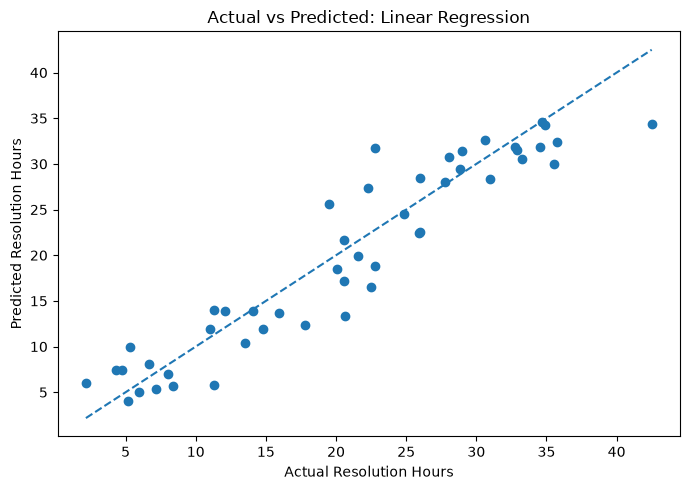

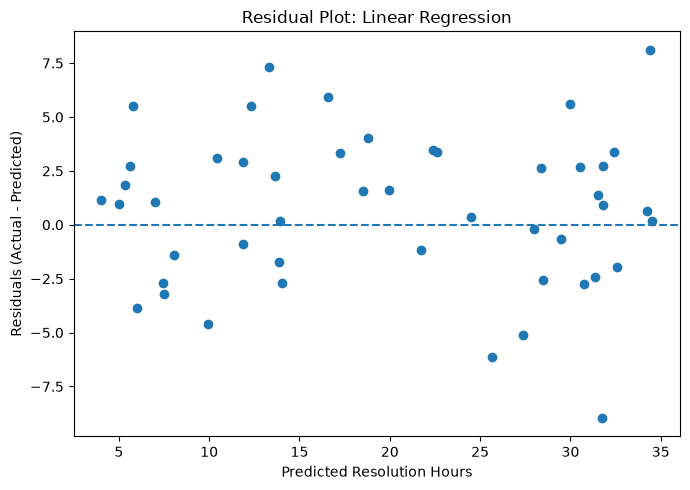

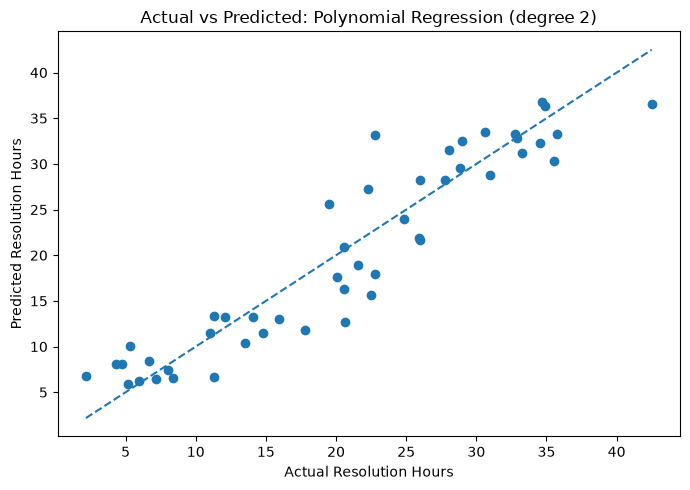

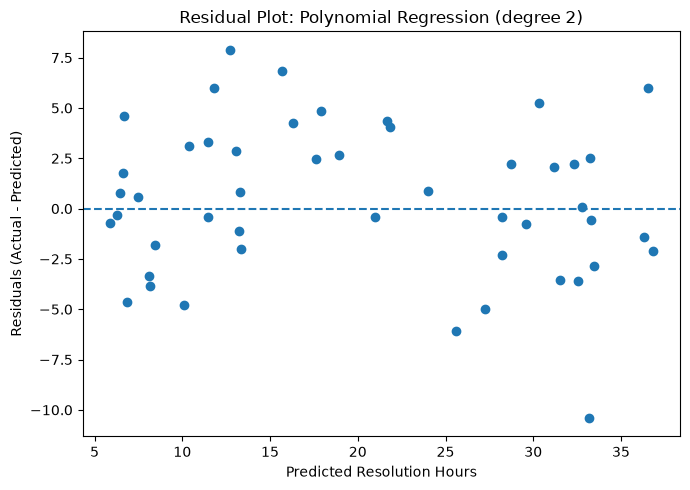

In [6]:
models_to_plot = {
    "Linear Regression": linear_model,
    f"Polynomial Regression (degree {best_degree})": polynomial_model
}

for name, model in models_to_plot.items():
    y_pred = model.predict(X_test)
    residuals = y_test - y_pred

    # Actual vs predicted plot
    plt.figure(figsize=(7, 5))
    plt.scatter(y_test, y_pred)
    min_value = min(y_test.min(), y_pred.min())
    max_value = max(y_test.max(), y_pred.max())
    plt.plot(
        [min_value, max_value],
        [min_value, max_value],
        linestyle="--"
    )
    plt.xlabel("Actual Resolution Hours")
    plt.ylabel("Predicted Resolution Hours")
    plt.title(f"Actual vs Predicted: {name}")
    plt.tight_layout()
    plt.show()

    # Residual plot
    plt.figure(figsize=(7, 5))
    plt.scatter(y_pred, residuals)
    plt.axhline(y=0, linestyle="--")
    plt.xlabel("Predicted Resolution Hours")
    plt.ylabel("Residuals (Actual - Predicted)")
    plt.title(f"Residual Plot: {name}")
    plt.tight_layout()
    plt.show()

Results and Discussion

1. Baseline
The Dummy Regressor predicts the mean resolution time for every ticket.
It provides a simple benchmark to determine whether the trained models
learn useful relationships from the selected features.

2. Model comparison
The model with the lowest test MAE was **[model name]**, with an MAE
of **[value]** hours. The model with the lowest test RMSE was
**[model name]**, with an RMSE of **[value]** hours. Its R² was
**[value]**.

3. Polynomial degree
Cross-validation was used to compare polynomial degrees 2 and 3.
Degree **[2 or 3]** achieved the lower mean validation MAE.
This indicates that **[briefly state whether the added complexity helped]**.

 4. Regularization and scaling
Ridge and Lasso were evaluated with scaled features, and their alpha
values were selected using cross-validation. Scaling is important
because regularization penalizes coefficient sizes, and features on
different scales can otherwise affect the penalty.

 5. Conclusion
I recommend **[best model]** for this experiment because it achieved
**[state the strongest evidence from the test results]**.
However, the dataset is synthetic, and further validation is needed
before applying the model to real support tickets.

 6. Limitations and deployment checks
- The dataset is synthetic and may not represent real ticket patterns.
- The available features may not capture all causes of resolution time.
- `lines_changed` and `reopened` may cause data leakage if used before
  those values become available.
- Real-world testing should use historical or future tickets, check
  prediction errors across teams and complexity levels, and monitor
  performance after deployment.

Analysis Questions and Answers

10. Why is the mean baseline useful even though it ignores all features?

The Dummy Regressor predicts the mean resolution time from the training data for every test ticket. It provides a simple benchmark. A useful regression model should perform better than this baseline by using information from the features.

11. Which model has the lowest MAE and RMSE? Are they the same, and why might they differ?

According to my test results, **[model with lowest MAE]** achieved the lowest MAE of **[value] hours**, while **[model with lowest RMSE]** achieved the lowest RMSE of **[value] hours**.

They **[are/are not]** the same model. MAE treats absolute errors proportionally, while RMSE penalizes large errors more heavily because the errors are squared before averaging.

12. Did polynomial features improve validation performance? What is the evidence of possible overfitting?

I compared polynomial degrees 2 and 3 using five-fold cross-validation on the training data. Degree **[2 or 3]** had the lower mean cross-validation MAE of **[value] hours**.

Polynomial features improve validation performance only if they reduce validation error compared with the simpler model. Possible overfitting is indicated when a model performs well on training data but worse on validation or unseen test data. A higher polynomial degree alone does not prove overfitting.

13. How did regularization affect performance and coefficient magnitudes?

Ridge and Lasso add penalties to the regression objective to discourage large coefficients. Ridge generally shrinks coefficients toward zero, while Lasso can shrink some coefficients to exactly zero.

In my experiment, Ridge achieved a test MAE of **[value]**, and Lasso achieved a test MAE of **[value]**. Compared with Linear Regression, their performance **[improved/remained similar/worsened]**. The selected alpha values were **[Ridge alpha]** for Ridge and **[Lasso alpha]** for Lasso.

14. Why is scaling included in the Ridge/Lasso pipeline?

Scaling places features on comparable scales. Ridge and Lasso penalize coefficient magnitudes, so features with different scales can otherwise be affected unevenly by the regularization penalty. Scaling helps make the penalty more meaningful across features.

15. Identify one potential leakage issue in the dataset and explain how you handled it.

The `lines_changed` feature describes the code changes made during a fix, so it may not be available when predicting resolution time at the beginning of a ticket. The `reopened` feature may also become known only after resolution. Using either too early could cause data leakage.

To reduce this risk, I excluded `lines_changed` and `reopened` from the prediction features and used `complexity_score` and `team_experience_years`, which are intended to be available at prediction time.

 16. Would a random split be appropriate if tickets were collected over several years or came from repeated customers or teams?

A random split may not be appropriate if the data contains time trends or repeated customers or teams. It can place related tickets in both training and test sets, making evaluation overly optimistic.

For time-dependent data, a chronological split is more appropriate: train on earlier tickets and test on later tickets. For repeated customers or teams, a group-based split can help test generalization to unseen groups.

 17. What additional tests would you perform before deploying this model?

Before deployment, I would:
- Evaluate the model on additional real historical tickets.
- Test on future tickets using a chronological split.
- Check errors across different complexity levels and teams.
- Investigate outliers and patterns in residual plots.
- Confirm that every feature is available at prediction time.
- Monitor prediction errors after deployment and retrain when necessary.

The dataset is synthetic, so its results alone are not enough to establish real-world performance.